In [1]:
import datetime
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [26]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261016


In [2]:
df = pd.read_pickle(f"../datasets/Processed/Averages_StrictlyQIFiltered_20261013.pkl")
df.shape

(2260, 48)

In [3]:
df["date_field"] = df["date"].astype(str) + "_" + df["field"].astype(str)
df.shape

(2260, 49)

In [4]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1/C2

In [5]:
print(df_c2.shape)
print(df_detano.shape)

(1102, 49)
(1158, 49)


In [6]:
df_c1_from_c2 = df_c2[df_c2["cond2"] == "C1"]
df_c1_from_no = df_detano[df_detano["cond2"] == "DETANO"]

print(df_c1_from_c2.shape)
print(df_c1_from_no.shape)

(551, 49)
(579, 49)


In [7]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [10]:
counts_c1_from_c2 = {}
counts_c1_from_no = {}

for cluster in cluster_ids:

    df_cluster_c2 = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == cluster]
    df_cluster_no = df_c1_from_no[df_c1_from_no["cluster_gchirp"] == cluster]

    counts_cluster_c2 = df_cluster_c2["date_field"].value_counts().sort_index()
    counts_cluster_no = df_cluster_no["date_field"].value_counts().sort_index()

    counts_c1_from_c2[str(cluster)] = counts_cluster_c2
    counts_c1_from_no[str(cluster)] = counts_cluster_no

counts_c1_from_c2 = pd.DataFrame(counts_c1_from_c2)
counts_c1_from_no = pd.DataFrame(counts_c1_from_no)

print(counts_c1_from_c2.shape)
print(counts_c1_from_no.shape)
    
# counts = pd.DataFrame(counts)
# counts

(5, 8)
(5, 8)


In [11]:
def calculate_cluster_thresholds(counts, n_clusters):
    """
    Calculate percentage thresholds and identify unique clusters
    and date_fields based on the proportion of cells per cluster.

    Parameters
    ----------
    counts : pandas.DataFrame
        DataFrame containing cluster counts per date_field.
        Rows represent date_fields and columns represent clusters.

    n_clusters : int
        Total number of clusters.

    Returns
    -------
    dict
        Dictionary containing:
        - threshold_pct: Percentage threshold.
        - total_cells: Total number of cells per date_field.
        - percentage_matrix: Percentage of cells per cluster.
        - above_threshold: Boolean matrix indicating threshold exceedance.
        - color_matrix: Binary matrix for visualization.
        - cluster_occurrences: Number of date_fields exceeding threshold per cluster.
        - unique_clusters: Clusters exceeding threshold in exactly one date_field.
        - unique_mask: Mask for clusters exceeding threshold in exactly one date_field.
        - field_cluster_occurrences: Number of clusters exceeding threshold per date_field.
        - single_cluster_fields: Date_fields with exactly one cluster exceeding threshold.
        - single_field_mask: Mask for highlighting those cells.
    """

    # Percentage threshold based on the number of clusters
    threshold_pct = 100 / n_clusters

    # Calculate the total number of cells for each date_field
    total_cells = counts.sum(axis=1)

    # Calculate the percentage of cells in each cluster per date_field
    percentage_matrix = counts.div(total_cells.replace(0, float("nan")), axis=0) * 100

    # Binary matrix for colours
    above_threshold = percentage_matrix >= threshold_pct
    color_matrix = above_threshold.astype(int)

    # Identify clusters that exceed the threshold in only one date_field
    cluster_occurrences = above_threshold.sum(axis=0)
    unique_clusters = cluster_occurrences[cluster_occurrences == 1].index

    # Mask for clusters above threshold in exactly one date_field
    unique_mask = (
        above_threshold
        & percentage_matrix.columns.isin(unique_clusters)
    )

    # Identify date_fields where exactly one cluster exceeds the threshold
    field_cluster_occurrences = above_threshold.sum(axis=1)
    single_cluster_fields = field_cluster_occurrences == 1

    # Mask for cells to highlight in magenta
    single_field_mask = (
        above_threshold
        & single_cluster_fields.to_numpy()[:, None]
    )

    return {
        "threshold_pct": threshold_pct,
        "total_cells": total_cells,
        "percentage_matrix": percentage_matrix,
        "above_threshold": above_threshold,
        "color_matrix": color_matrix,
        "cluster_occurrences": cluster_occurrences,
        "unique_clusters": unique_clusters,
        "unique_mask": unique_mask,
        "field_cluster_occurrences": field_cluster_occurrences,
        "single_cluster_fields": single_cluster_fields,
        "single_field_mask": single_field_mask,
    }

In [12]:
c2 = calculate_cluster_thresholds(counts_c1_from_c2, n_clusters)
no = calculate_cluster_thresholds(counts_c1_from_no, n_clusters)

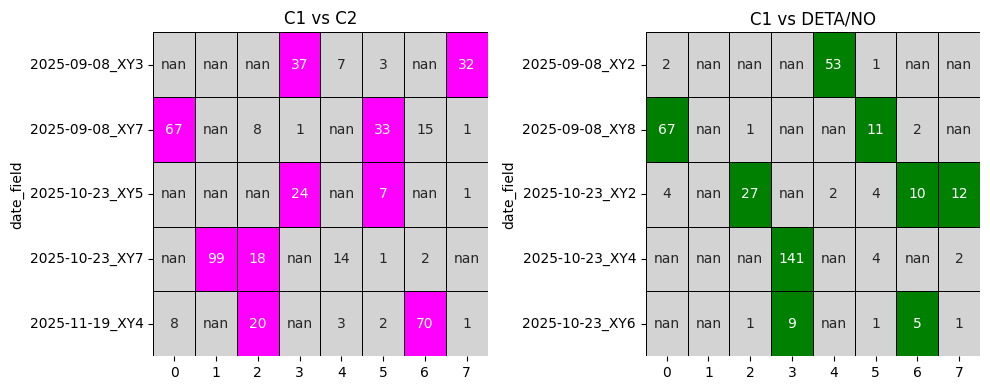

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(10,4))

# Base heatmap: below threshold = gray, above threshold = blue
sns.heatmap(
    c2["color_matrix"],
    annot=counts_c1_from_c2,
    fmt=".0f",
    cmap=sns.color_palette(["lightgray", "magenta"]),
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="black",
    cbar=False,
    ax=axs[0]
)

# Base heatmap: below threshold = gray, above threshold = blue
sns.heatmap(
    no["color_matrix"],
    annot=counts_c1_from_no,
    fmt=".0f",
    cmap=sns.color_palette(["lightgrey", "green"]),
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="black",
    cbar=False,
    ax=axs[1]
)

axs[0].set_title("C1 vs C2")
axs[1].set_title("C1 vs DETA/NO")

plt.tight_layout()
plt.savefig(f"../plots/clustering/nROIs_Heatmap_Condition_StrictFilter_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()